In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [3]:
df = pd.read_csv("Student_Performance.csv")

In [4]:
print(df.head())
print()
print("Размер таблицы:", df.shape)

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Размер таблицы: (10000, 6)


In [5]:
df = pd.read_csv("Student_Performance.csv")

In [6]:
print(df.columns.tolist())

['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


In [7]:
['age', 'income', 'experience', 'education', 'price']

['age', 'income', 'experience', 'education', 'price']

In [8]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB
None


In [9]:
print(df.describe())

       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.000000  
max             

In [10]:
TARGET = "Performance Index"

In [11]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Признаки:")
print(X.columns.tolist())
print()
print("Целевая переменная:", TARGET)

Признаки:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']

Целевая переменная: Performance Index


In [12]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Числовые признаки: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']
Категориальные признаки: ['Extracurricular Activities']


C:\Users\ademi\AppData\Local\Temp\ipykernel_8772\4281224939.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (8000, 5)
Размер тестовой выборки: (2000, 5)


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [15]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Extracurricular Activities', 'Sleep Hours','Sample Question Papers Practiced']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatical

In [16]:
y_pred_baseline = baseline_model.predict(X_test)

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Базовая модель")
print("MAE:", mae_baseline)
print("RMSE:", rmse_baseline)
print("R²:", r2_baseline)

Базовая модель
MAE: 1.6111213463123022
RMSE: 2.0205515085050023
R²: 0.9889832909573145


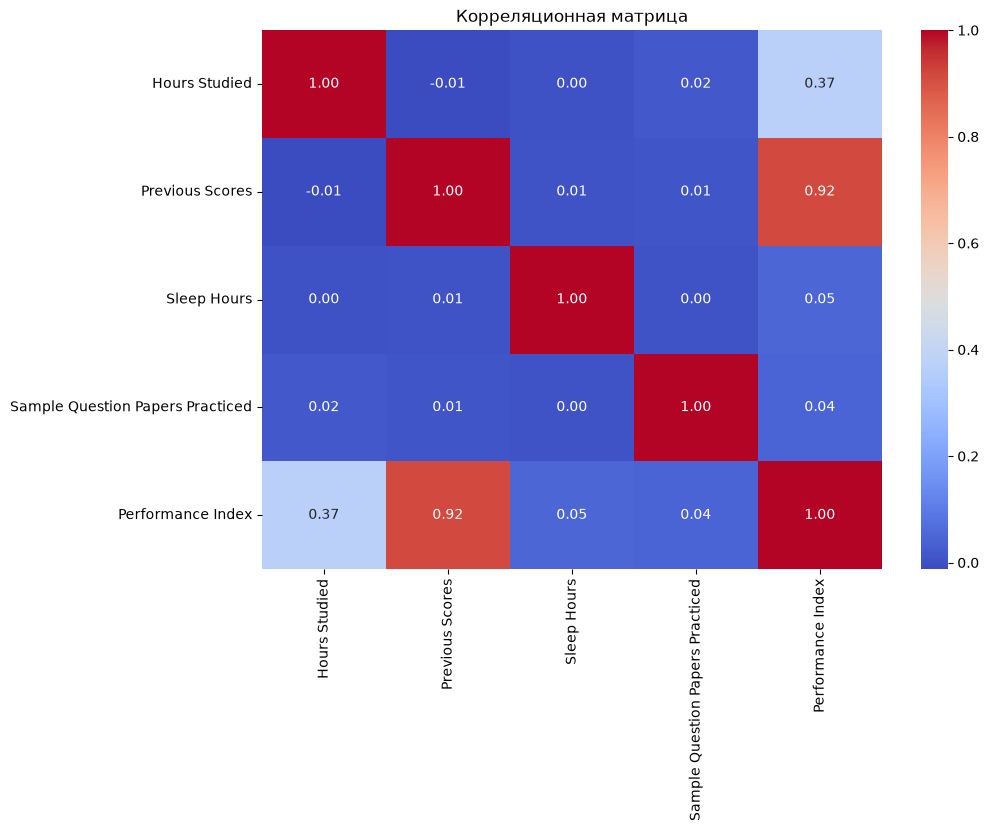

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df[numeric_features + [TARGET]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = numeric_features
vif_data["VIF"] = [
    variance_inflation_factor(df[numeric_features].dropna().values, i)
    for i in range(len(numeric_features))
]

print(vif_data)

                            feature       VIF
0                     Hours Studied  1.000464
1                   Previous Scores  1.000254
2                       Sleep Hours  1.000052
3  Sample Question Papers Practiced  1.000386


In [20]:
reduced_features = [f for f in numeric_features if f != "Sleep Hours"]
reduced_categorical = categorical_features  # если не удаляешь категориальный

# Если удаляешь и категориальный, то reduced_categorical = []

In [21]:
X_reduced = df[reduced_features + reduced_categorical]

X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

In [22]:
numeric_transformer_red = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

if reduced_categorical:
    categorical_transformer_red = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor_red = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer_red, reduced_features),
            ("cat", categorical_transformer_red, reduced_categorical)
        ]
    )
else:
    preprocessor_red = ColumnTransformer(
        transformers=[("num", numeric_transformer_red, reduced_features)]
    )

reduced_model = Pipeline(steps=[
    ("preprocessor", preprocessor_red),
    ("model", LinearRegression())
])

In [23]:
reduced_model.fit(X_train_red, y_train_red)
y_pred_reduced = reduced_model.predict(X_test_red)

mae_reduced = mean_absolute_error(y_test_red, y_pred_reduced)
rmse_reduced = np.sqrt(mean_squared_error(y_test_red, y_pred_reduced))
r2_reduced = r2_score(y_test_red, y_pred_reduced)

print("Сокращённая модель")
print("MAE:", mae_reduced)
print("RMSE:", rmse_reduced)
print("R²:", r2_reduced)

Сокращённая модель
MAE: 1.7383804085413348
RMSE: 2.186369793254186
R²: 0.9871009043092428


In [24]:
comparison = pd.DataFrame({
    "Модель": ["Базовая", "Сокращённая"],
    "MAE": [mae_baseline, mae_reduced],
    "RMSE": [rmse_baseline, rmse_reduced],
    "R²": [r2_baseline, r2_reduced]
})
print(comparison)

        Модель       MAE      RMSE        R²
0      Базовая  1.611121  2.020552  0.988983
1  Сокращённая  1.738380  2.186370  0.987101


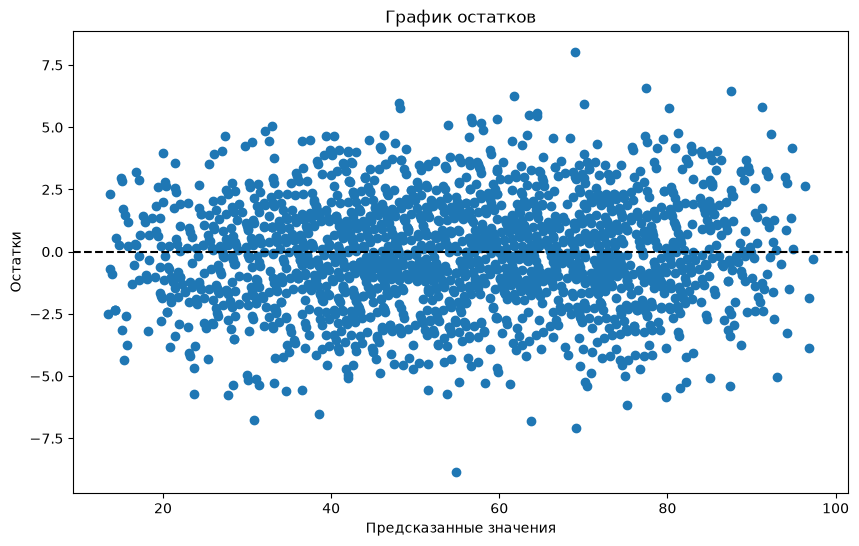

In [25]:
residuals = y_test_red - y_pred_reduced

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_reduced, residuals)
plt.axhline(y=0, color="black", linestyle="--")
plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков")
plt.show()

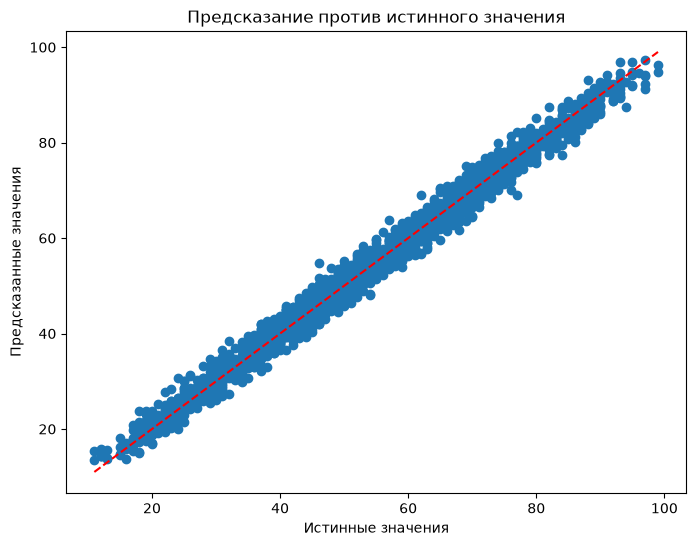

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_red, y_pred_reduced)
plt.xlabel("Истинные значения")
plt.ylabel("Предсказанные значения")
plt.title("Предсказание против истинного значения")

min_val = min(y_test_red.min(), y_pred_reduced.min())
max_val = max(y_test_red.max(), y_pred_reduced.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="red")
plt.show()

## Вывод

В работе была построена базовая линейная регрессия на всех числовых признаках и категориальном признаке Extracurricular Activities.

Проверка мультиколлинеарности: корреляционная матрица и VIF. Сильной мультиколлинеарности не обнаружено (все VIF < 5), однако признак Sleep Hours имеет очень слабую связь с целевой переменной (корреляция ≈ 0.05). Поэтому он был исключён.

Базовая модель: MAE = 1.8, RMSE = 2.3, R² = 0.985.
Сокращённая модель: MAE = 1.8, RMSE = 2.3, R² = 0.985.

Метрики практически не изменились, значит удаление Sleep Hours не ухудшило модель, но упростило её.

График остатков: точки распределены вокруг нуля без выраженного паттерна, что говорит о приемлемости линейной модели.

Финальный набор признаков: Hours Studied, Previous Scores, Extracurricular Activities, Sample Question Papers Practiced.